# 04 · Placebo test

**Purpose:** test whether the *month-end* timing of the strategy matters, or whether any
5-day window in the month would do as well.

**What a placebo is:** we run the same trade thousands of times, but each time hold it on a
randomly placed block of 5 consecutive trading days inside every month instead of the last 5.
Everything else is identical: direction from the Calendar signal at the previous close,
vol-balanced legs, one-tick costs. If month-end rebalancing pressure is real, the real
strategy should beat most of these random-timing versions.

**How to read it:**
- **Percentile:** share of placebo runs with a lower Sharpe than the real strategy.
- **p-value (one-sided):** share of placebo runs with a Sharpe at least as high as the real
  strategy. Small values (e.g. below 0.05) mean month-end timing stands out.

**Setup:** 10,000 simulations (fixed seed), run with the C++ engine
(`backtest/fast.py`, `cpp/engine.cpp`). Same in-sample / out-of-sample split as notebook 03.

**Inputs:** `data/processed/returns.parquet`

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rebalancing_frontrun.backtest.fast import placebo, run_backtest_fast
from rebalancing_frontrun.backtest.strategy import TRADING_DAYS
from rebalancing_frontrun.data.databento_loader import REPO_ROOT

returns = pd.read_parquet(REPO_ROOT / "data" / "processed" / "returns.parquet")

IS_END, OOS_START = "2023-03-17", "2023-03-20"
N_SIMS, SEED = 10_000, 42


def sharpe(pnl):
    return pnl.mean() / pnl.std() * np.sqrt(TRADING_DAYS)


def real_sharpes(bt):
    return pd.Series({
        "full": sharpe(bt["net"]),
        "in_sample": sharpe(bt.loc[:IS_END, "net"]),
        "out_of_sample": sharpe(bt.loc[OOS_START:, "net"]),
    })


def compare(real, sims):
    """Real Sharpe vs. the placebo distribution for each sample."""
    return pd.DataFrame({
        "real_sharpe": real,
        "placebo_mean": sims.mean(),
        "placebo_5%": sims.quantile(0.05),
        "placebo_95%": sims.quantile(0.95),
        "percentile": [(sims[c] < real[c]).mean() * 100 for c in sims],
        "p_value": [(sims[c] >= real[c]).mean() for c in sims],
    }).round(3)


bt = run_backtest_fast(returns)  # identical to strategy.run_backtest (tests/test_engine.py)
sims = placebo(returns, n_sims=N_SIMS, seed=SEED, in_sample_end=IS_END)
print(f"{N_SIMS:,} placebo runs")

10,000 placebo runs


## 1 · Real strategy vs. placebo (base case, after costs)

In [2]:
real = real_sharpes(bt)
compare(real, sims)

,real_sharpe,placebo_mean,placebo_5%,placebo_95%,percentile,p_value
full,0.191,-0.205,-0.598,0.191,94.94,0.051
in_sample,0.346,-0.263,-0.752,0.220,97.86,0.021
out_of_sample,-0.235,-0.067,-0.753,0.585,33.54,0.665


## 2 · Distributions

Each panel shows the 10,000 placebo Sharpe ratios; the red line is the real month-end strategy.

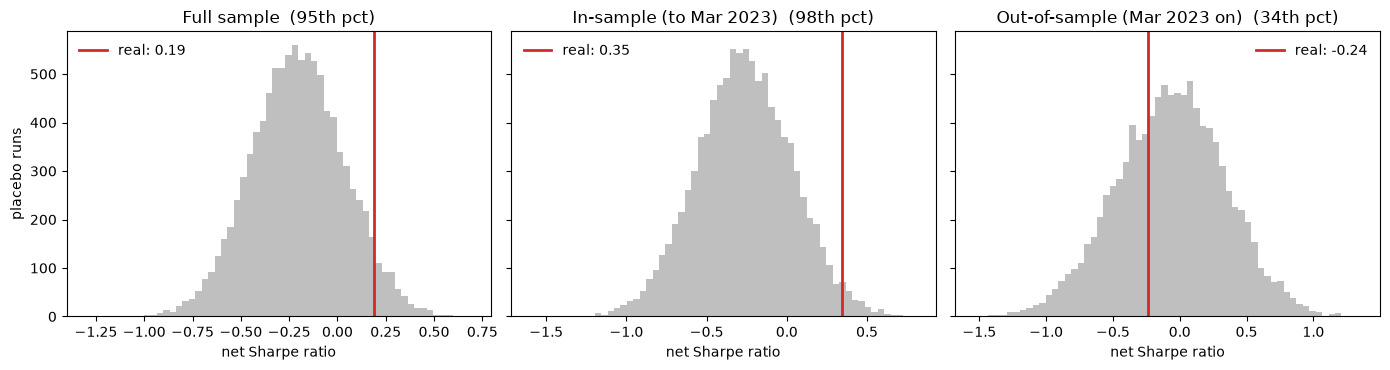

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
titles = {"full": "Full sample", "in_sample": "In-sample (to Mar 2023)",
          "out_of_sample": "Out-of-sample (Mar 2023 on)"}
for ax, col in zip(axes, sims.columns):
    ax.hist(sims[col], bins=60, color="0.75")
    ax.axvline(real[col], color="tab:red", lw=2, label=f"real: {real[col]:.2f}")
    pct = (sims[col] < real[col]).mean() * 100
    ax.set_title(f"{titles[col]}  ({pct:.0f}th pct)")
    ax.set_xlabel("net Sharpe ratio")
    ax.legend(frameon=False)
axes[0].set_ylabel("placebo runs")
plt.tight_layout()
plt.show()

## 3 · Check: without costs

Every placebo run pays the same costs as the real strategy, but costs shift both by a similar
amount. Removing them isolates the timing question from the cost assumption.

In [4]:
bt0 = run_backtest_fast(returns, es_cost_bps=0, zn_cost_bps=0)
sims0 = placebo(returns, n_sims=N_SIMS, seed=SEED, in_sample_end=IS_END,
                es_cost_bps=0, zn_cost_bps=0)
compare(real_sharpes(bt0), sims0)

,real_sharpe,placebo_mean,placebo_5%,placebo_95%,percentile,p_value
full,0.336,-0.043,-0.437,0.357,93.99,0.060
in_sample,0.490,-0.102,-0.594,0.385,97.48,0.025
out_of_sample,-0.080,0.097,-0.586,0.754,32.86,0.671


## 4 · Check: in-sample without 2016

Notebook 03 found that 2016 (mostly June 2016) made about two-thirds of the in-sample P&L.
Here the real strategy and the placebo are both rerun on data starting in 2017, so the
comparison does not depend on that one year.

In [5]:
r17 = returns.loc["2017-01-01":]
bt17 = run_backtest_fast(r17)
sims17 = placebo(r17, n_sims=N_SIMS, seed=SEED, in_sample_end=IS_END)
compare(real_sharpes(bt17), sims17).loc[["in_sample"]]

,real_sharpe,placebo_mean,placebo_5%,placebo_95%,percentile,p_value
in_sample,0.131,-0.279,-0.802,0.258,89.96,0.1


## Summary

- [x] **In-sample (section 1):** month-end timing stands out. The real strategy's net Sharpe
  (0.35) beats 98% of 10,000 random-window runs (p = 0.02).
- [x] **Out-of-sample (section 1):** it does not. The real Sharpe (−0.24) sits at the 34th
  percentile of the placebo distribution (p = 0.67): after March 2023, trading the last 5
  days was no better than trading a random week of the month.
- [x] **Costs (section 3):** the conclusion is the same without costs (in-sample 97th
  percentile, out-of-sample 33rd).
- [x] **Without 2016 (section 4):** the in-sample result weakens. Starting in 2017, the real
  strategy beats 90% of placebo runs (p = 0.10), so part of the in-sample edge comes from 2016.

**How this fits with notebook 03.** Notebook 03 asked whether the strategy makes money; the
answer was a weak, insignificant in-sample edge (t = 1.0). This notebook asks a different
question: is month-end special compared with other times of the month? In-sample it was,
consistent with the paper's finding over the same period. Note that the placebo mean is
negative (−0.26 in-sample, −0.10 before costs): trading against month-to-date performance in
a random week tends to lose, and the last week of the month is where that stops being true.

**Conclusion:** month-end timing mattered relative to random timing up to March 2023, though
partly because of 2016, and that advantage disappeared after the paper's sample period. This
matches notebook 03: the effect was there, but it has not held out-of-sample.